# 15 — Końcowa ocena wykrywania spekulacyjnych anomalii BTC
Rozdzielamy **trzy różne zadania**:
(1) zgodność z etykietami BSADF (model był na nich uczony),
(2) retrospektywna zgodność z literaturowymi UNION (niezależność częściowa),
(3) przyszłe korekty ceny po alarmie (ryzyko prognostyczne).
Wyniki 2021–2024 są OOS chronologicznie, lecz przy wielokrotnej analizie
całego okresu NIE są całkowicie dziewiczym testem końcowym.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bubble_tools import (UNION_EPISODES,load_prices,future_drop_labels,
                          classification_stats,onsets)

ROOT=Path('.')
OUT=ROOT/'15_wyniki_bubble'
OUT.mkdir(exist_ok=True,parents=True)
PRED_FILE=ROOT/'14_wyniki_bubble'/'14_bubble_detection_predictions_OOS.csv'
REF_FILE=ROOT/'13_wyniki_bubble'/'13_bubble_reference_daily.csv'
if not PRED_FILE.exists():raise FileNotFoundError('Uruchom 14, aby uzyskać prognozy OOS')
if not REF_FILE.exists():raise FileNotFoundError('Uruchom 13')

D=10;H=60
PREWARNING_DAYS=30
VIEW_MODEL='XGBoost'
VIEW_GROUP='Price+LPPLS'

pred=pd.read_csv(PRED_FILE,parse_dates=['date'])
ref=pd.read_csv(REF_FILE,parse_dates=['date'])
prices=load_prices(REF_FILE)
fut=future_drop_labels(prices,thresholds=(10,15,20),horizons=(30,45,60))
assert pred.groupby(['model','feature_group']).date.apply(lambda s:s.is_unique).all()
assert set(pred.y.unique()).issubset({0,1})
assert (pred['y_pred'].isin([0,1])).all()

## 1. Metryki dzienne: cecha referencyjna BSADF vs UNION
Obie walidacje mają różną interpretację. Wynik vs BSADF nie jest
niezależnym sprawdzianem zdolności znajdowania ekonomicznych baniek.

In [2]:
rows=[]
for (model,group),p in pred.groupby(['model','feature_group']):
    p=p.sort_values('date')
    for target,name in [('y','asof_BSADF_proxy'),('bubble_union','historical_UNION')]:
        stat=classification_stats(p[target],p.y_pred,p.score)
        rows.append({'model':model,'feature_group':group,'target':name,**stat})
metrics=pd.DataFrame(rows)
metrics.to_csv(OUT/'15_01_daily_detection_metrics.csv',index=False)
display(metrics[['model','feature_group','target','positive_rate','AP','f1','recall','specificity','time_in_alarm']].round(3))

,model,feature_group,target,positive_rate,AP,f1,recall,specificity,time_in_alarm
0,CI_gt_0,LPPLS-rule,asof_BSADF_proxy,0.138,0.144,0.169,0.139,0.920,0.088
1,CI_gt_0,LPPLS-rule,historical_UNION,0.181,0.202,0.209,0.155,0.926,0.088
2,CI_gt_0.05,LPPLS-rule,asof_BSADF_proxy,0.138,0.144,0.169,0.139,0.920,0.088
3,CI_gt_0.05,LPPLS-rule,historical_UNION,0.181,0.202,0.209,0.155,0.926,0.088
4,LogisticRegression,LPPLS-only,asof_BSADF_proxy,0.138,0.187,0.064,0.035,0.991,0.012
5,LogisticRegression,LPPLS-only,historical_UNION,0.181,0.369,0.092,0.049,0.996,0.012
6,LogisticRegression,Price+LPPLS,asof_BSADF_proxy,0.138,0.603,0.583,0.703,0.886,0.195
7,LogisticRegression,Price+LPPLS,historical_UNION,0.181,0.644,0.568,0.591,0.892,0.195
8,LogisticRegression,Price-only,asof_BSADF_proxy,0.138,0.662,0.586,0.634,0.915,0.161
9,LogisticRegression,Price-only,historical_UNION,0.181,0.676,0.521,0.492,0.912,0.161


## 2. Czy alarmy wykrywają całe epizody UNION?
`detected_inside`: aktywny alarm w dowolnym dniu epizodu.
`early_onset`: NOWE ostrzeżenie w (start - PREWARNING_DAYS, start),
z wykluczeniem samego dnia startu i lewostronnego cenzurowania.
Jeśli epizod rozpoczął się przed pierwszą prognozą OOS, nie oceniamy
jego wczesnego ostrzegania jako pełnego epizodu.

In [3]:
events=pd.DataFrame(UNION_EPISODES,columns=['bubble_id','start','end'])
events['start']=pd.to_datetime(events.start);events['end']=pd.to_datetime(events.end)
rows=[];onset_rows=[]
for (model,group),p in pred.groupby(['model','feature_group']):
    p=p.sort_values('date').reset_index(drop=True)
    sig=onsets(p.rename(columns={'y_pred':'alarm'}),'alarm')
    starts=sig.loc[sig.onset==1,'date']
    # Nie liczymy początku serii jako nowego ostrzeżenia, jeśli model już wtedy alarmuje.
    for ep in events.itertuples(index=False):
        if ep.start<p.date.min() or ep.end>p.date.max():continue
        inside=p.date.between(ep.start,ep.end)
        pre=starts.loc[(starts<ep.start)&(starts>=ep.start-pd.Timedelta(days=PREWARNING_DAYS))]
        rows.append({'model':model,'feature_group':group,'bubble_id':ep.bubble_id,
                     'start':ep.start,'end':ep.end,'n_days':int(inside.sum()),
                     'alarm_days_in_episode':int(p.loc[inside,'y_pred'].sum()),
                     'detected_inside':int((p.loc[inside,'y_pred']==1).any()),
                     'active_on_start':int(bool(p.loc[p.date.eq(ep.start),'y_pred'].eq(1).any())),
                     'prewarning_by_new_onset':int(len(pre)>0),
                     'lead_days_from_nearest_onset':(ep.start-pre.max()).days if len(pre) else np.nan,
                     'new_onsets_inside':int(starts.between(ep.start,ep.end).sum())})
    out=sig.loc[sig.onset==1,['date']].copy()
    out['model']=model;out['feature_group']=group
    onset_rows.append(out)
per_episode=pd.DataFrame(rows)
per_episode.to_csv(OUT/'15_02_UNION_episode_detection.csv',index=False)
display(per_episode.head(10))

,model,feature_group,bubble_id,start,end,n_days,alarm_days_in_episode,detected_inside,active_on_start,prewarning_by_new_onset,lead_days_from_nearest_onset,new_onsets_inside
0,CI_gt_0,LPPLS-rule,UNION12,2021-08-08,2021-09-19,43,10,1,0,1,3.0,7
1,CI_gt_0,LPPLS-rule,UNION13,2021-10-05,2021-12-02,59,6,1,0,1,26.0,3
2,CI_gt_0,LPPLS-rule,UNION14,2024-03-04,2024-03-25,22,13,1,1,1,7.0,6
3,CI_gt_0.05,LPPLS-rule,UNION12,2021-08-08,2021-09-19,43,10,1,0,1,3.0,7
4,CI_gt_0.05,LPPLS-rule,UNION13,2021-10-05,2021-12-02,59,6,1,0,1,26.0,3
5,CI_gt_0.05,LPPLS-rule,UNION14,2024-03-04,2024-03-25,22,13,1,1,1,7.0,6
6,LogisticRegression,LPPLS-only,UNION12,2021-08-08,2021-09-19,43,0,0,0,0,NaN,0
7,LogisticRegression,LPPLS-only,UNION13,2021-10-05,2021-12-02,59,6,1,0,0,NaN,3
8,LogisticRegression,LPPLS-only,UNION14,2024-03-04,2024-03-25,22,0,0,0,0,NaN,0
9,LogisticRegression,Price+LPPLS,UNION12,2021-08-08,2021-09-19,43,16,1,1,1,12.0,4


## 3. Czy NOWE sygnały poprzedzają późniejsze spadki?
Dla daty pierwszego alarmu sprawdzamy przyszły min(P)/P_t na pełnym H.
Nie oceniamy ostatnich H dni bez pełnego horyzontu. **To NIE jest**
to samo co wykrywanie anomalii w bieżącym dniu.

In [4]:
onset_per_model=[];onset_details=[]
for (model,group),p in pred.groupby(['model','feature_group']):
    p=p.sort_values('date').reset_index(drop=True)
    sig=onsets(p.rename(columns={'y_pred':'alarm'}),'alarm')
    sig=sig.loc[sig.onset==1,['date']].merge(
        fut[['date',f'drop_{D}_h{H}',f'label_end_{H}']],on='date',how='left',validate='one_to_one')
    sig['model']=model;sig['feature_group']=group
    sig['assessable']=sig[f'drop_{D}_h{H}'].notna()
    sig['correct_future_warning']=sig[f'drop_{D}_h{H}'].eq(1)
    onset_details.append(sig)
    eligible=sig.loc[sig.assessable]
    days=(p.date.max()-p.date.min()).days+1
    union_sub=per_episode.loc[(per_episode.model==model)&(per_episode.feature_group==group)]
    onset_per_model.append({
        'model':model,'feature_group':group,'D_pct':D,'H_days':H,
        'OOS_days':len(p),'time_in_alarm':float(p.y_pred.mean()),
        'new_warning_onsets_total':int(len(sig)),
        'new_warning_onsets_evaluable':int(len(eligible)),
        'new_warning_followed_by_drop':int(eligible.correct_future_warning.sum()),
        'new_warning_not_followed_by_drop':int((eligible[f'drop_{D}_h{H}']==0).sum()),
        'unconfirmed_onsets_per_year':float((eligible[f'drop_{D}_h{H}']==0).sum()*365.25/days),
        'union_episodes':len(union_sub),
        'union_event_recall_active':float(union_sub.detected_inside.mean()) if len(union_sub) else np.nan,
        'union_prewarning_recall_onset':float(union_sub.prewarning_by_new_onset.mean()) if len(union_sub) else np.nan,
        'median_prewarning_lead_days':float(union_sub.lead_days_from_nearest_onset.median()) if union_sub.prewarning_by_new_onset.any() else np.nan,
    })
summary=pd.DataFrame(onset_per_model)
summary.to_csv(OUT/'15_03_warning_utility_OOS.csv',index=False)
pd.concat(onset_details,ignore_index=True).to_csv(OUT/'15_04_onsets_and_future_declines.csv',index=False)
display(summary.round(3))

,model,feature_group,D_pct,H_days,OOS_days,time_in_alarm,new_warning_onsets_total,new_warning_onsets_evaluable,new_warning_followed_by_drop,new_warning_not_followed_by_drop,unconfirmed_onsets_per_year,union_episodes,union_event_recall_active,union_prewarning_recall_onset,median_prewarning_lead_days
0,CI_gt_0,LPPLS-rule,10,60,1461,0.088,72,69,46,23,5.75,3,1.000,1.000,7.0
1,CI_gt_0.05,LPPLS-rule,10,60,1461,0.088,72,69,46,23,5.75,3,1.000,1.000,7.0
2,LogisticRegression,LPPLS-only,10,60,1461,0.012,11,11,11,0,0.00,3,0.333,0.000,NaN
3,LogisticRegression,Price+LPPLS,10,60,1461,0.195,30,26,19,7,1.75,3,1.000,1.000,12.0
4,LogisticRegression,Price-only,10,60,1461,0.161,23,19,12,7,1.75,3,1.000,0.667,7.5
5,XGBoost,LPPLS-only,10,60,1461,0.018,21,21,15,6,1.50,3,1.000,0.333,5.0
6,XGBoost,Price+LPPLS,10,60,1461,0.188,36,32,20,12,3.00,3,1.000,1.000,11.0
7,XGBoost,Price-only,10,60,1461,0.166,26,22,13,9,2.25,3,1.000,0.667,4.0


## 3b. Wartość dodana LPPLS w wykrywaniu proxy BSADF — bootstrap blokowy
ΔAP = AP(XGBoost Price+LPPLS) - AP(XGBoost Price-only)
Wyniki bootstrapa nie są niezależną walidacją nowego okresu.

In [5]:
from sklearn.metrics import average_precision_score
BOOTSTRAP_REPS=600
BLOCK_SIZES=[30,60,90]
RANDOM_SEED=42
left=pred.loc[(pred.model=='XGBoost')&(pred.feature_group=='Price+LPPLS'),
              ['date','y','score']].rename(columns={'score':'score_hybrid'})
right=pred.loc[(pred.model=='XGBoost')&(pred.feature_group=='Price-only'),
               ['date','y','score']].rename(columns={'score':'score_price','y':'y_price'})
paired=left.merge(right,on='date',validate='one_to_one').sort_values('date').reset_index(drop=True)
if len(paired)!=len(left) or len(paired)!=len(right) or not paired.y.eq(paired.y_price).all():
    raise ValueError('Predykcje modeli nie są sparowane na tych samych dniach i etykietach')
observed_delta=(average_precision_score(paired.y,paired.score_hybrid)
                -average_precision_score(paired.y,paired.score_price))
ci_rows=[]
for block in BLOCK_SIZES:
    rng=np.random.default_rng(RANDOM_SEED+block)
    samples=[]
    for rep in range(BOOTSTRAP_REPS):
        # Losowanie bloków WEWNĄTRZ każdego roku, bez przechodzenia jego granicy.
        picks=[]
        for _,yr in paired.groupby(paired.date.dt.year):
            ix=yr.index.to_numpy()
            k=len(ix)
            blocks=[]
            while len(blocks)<k:
                start=int(rng.integers(0,k))
                blocks.extend(ix[np.arange(start,start+block)%k].tolist())
            picks.extend(blocks[:k])
        y=paired.loc[picks,'y']
        if y.nunique()<2:continue
        samples.append(average_precision_score(y,paired.loc[picks,'score_hybrid'])
                       -average_precision_score(y,paired.loc[picks,'score_price']))
    ci_rows.append({'model':'XGBoost','label':'BSADF_asof_proxy',
        'block_days':block,'observed_delta_AP':observed_delta,
        'bootstrap_n':len(samples),
        'ci95_low':float(np.quantile(samples,.025)) if samples else np.nan,
        'ci95_high':float(np.quantile(samples,.975)) if samples else np.nan})
bootstrap=pd.DataFrame(ci_rows)
bootstrap.to_csv(OUT/'15_05_paired_deltaAP_BSADF_bootstrap.csv',index=False)
display(bootstrap.round(4))

,model,label,block_days,observed_delta_AP,bootstrap_n,ci95_low,ci95_high
0,XGBoost,BSADF_asof_proxy,30,-0.0145,600,-0.0520,0.0285
1,XGBoost,BSADF_asof_proxy,60,-0.0145,600,-0.0575,0.0178
2,XGBoost,BSADF_asof_proxy,90,-0.0145,599,-0.0528,0.0110


## 4. Wykres: cena, UNION, referencja BSADF i FAKTYCZNE dni alarmowe
Nie łączymy dni z alarmem przez tolerancję ciszy.

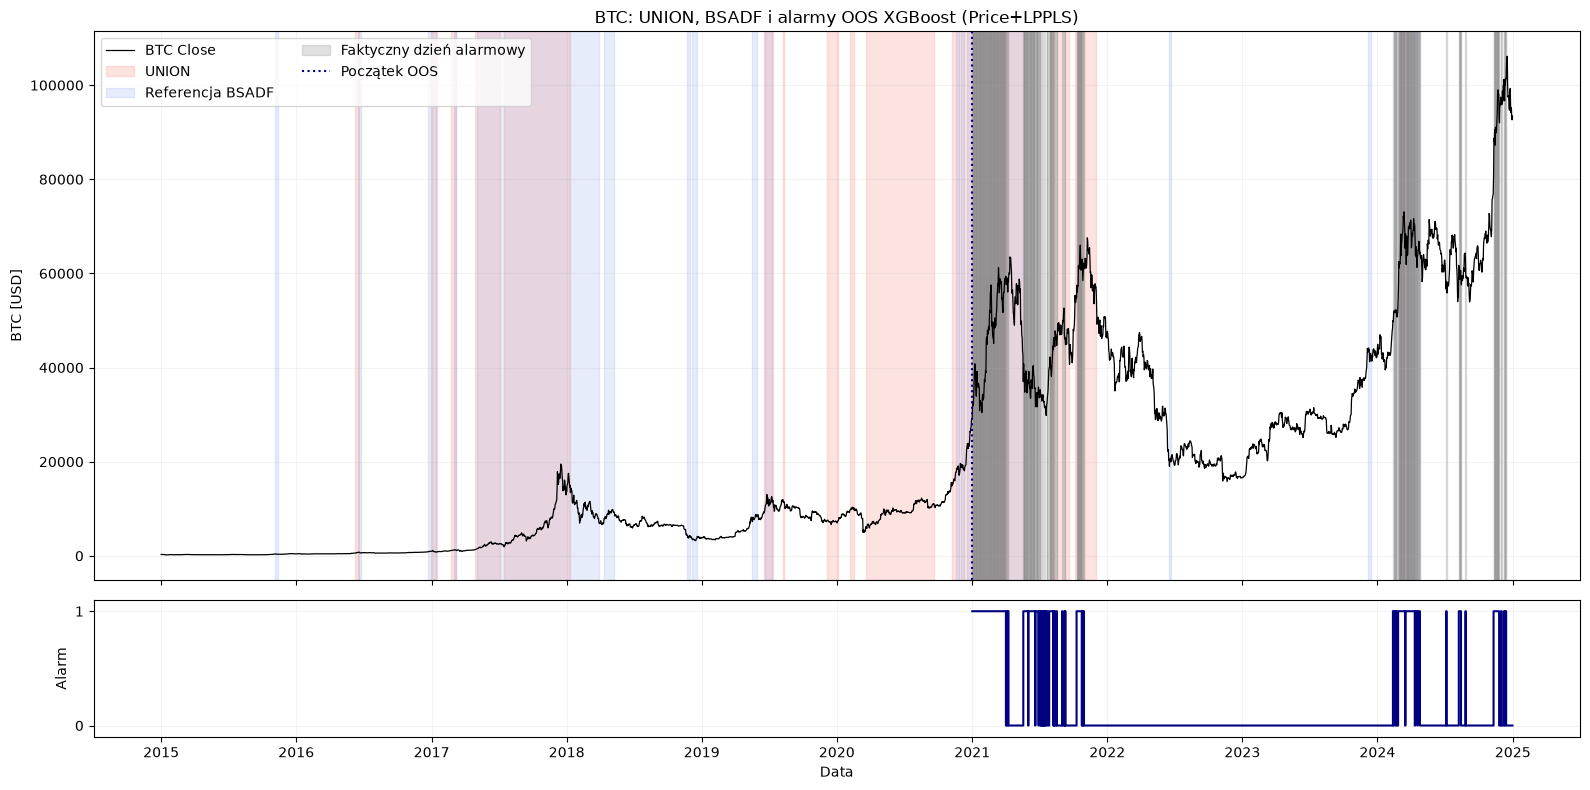

In [6]:
chosen=pred.loc[(pred.model==VIEW_MODEL)&(pred.feature_group==VIEW_GROUP)].sort_values('date').copy()
if chosen.empty:raise ValueError('Brak predykcji dla wybranego modelu/grupy')
fig,(ax,ax2)=plt.subplots(2,1,figsize=(16,8),sharex=True,
                           gridspec_kw={'height_ratios':[4,1]})
ax.plot(prices.date,prices.price,color='black',lw=.9,label='BTC Close')
for i,ep in events.iterrows():
    ax.axvspan(ep['start'],ep['end'],color='salmon',alpha=.22,label='UNION' if i==0 else None)
rs=ref.bubble_state_gsadf.fillna(0).astype(int).to_numpy()
starts=np.where((rs==1)&(np.r_[0,rs[:-1]]==0))[0]
ends=np.where((rs==1)&(np.r_[rs[1:],0]==0))[0]
for j,(a,b) in enumerate(zip(starts,ends)):
    ax.axvspan(ref.date.iloc[a],ref.date.iloc[b]+pd.Timedelta(days=1),
               color='royalblue',alpha=.12,label='Referencja BSADF' if j==0 else None)
for i,t in enumerate(chosen.loc[chosen.y_pred==1,'date']):
    ax.axvspan(t,t+pd.Timedelta(days=1),color='grey',alpha=.23,
               label='Faktyczny dzień alarmowy' if i==0 else None)
ax.axvline(chosen.date.min(),ls=':',color='navy',label='Początek OOS')
ax.set(title=f'BTC: UNION, BSADF i alarmy OOS {VIEW_MODEL} ({VIEW_GROUP})',ylabel='BTC [USD]')
ax.legend(loc='upper left',ncol=2);ax.grid(alpha=.15)
ax2.step(chosen.date,chosen.y_pred,where='post',color='navy')
ax2.set(ylim=(-.1,1.1),yticks=[0,1],ylabel='Alarm',xlabel='Data')
ax2.grid(alpha=.15)
fig.tight_layout();fig.savefig(OUT/'15_01_price_UNION_BSADF_ML.png',dpi=170);plt.show()

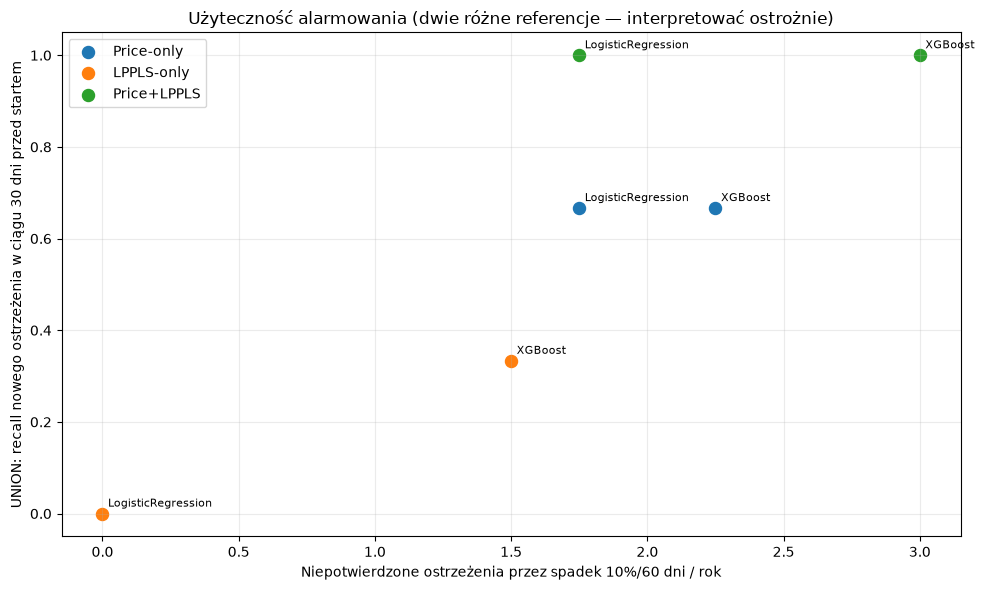

In [7]:
fig,ax=plt.subplots(figsize=(10,6))
for group,color in [('Price-only','tab:blue'),('LPPLS-only','tab:orange'),('Price+LPPLS','tab:green')]:
    p=summary[summary.feature_group==group]
    if len(p):ax.scatter(p.unconfirmed_onsets_per_year,p.union_prewarning_recall_onset,
                         label=group,s=75,color=color)
    for r in p.itertuples():
        ax.annotate(r.model,(r.unconfirmed_onsets_per_year,r.union_prewarning_recall_onset),
                    xytext=(4,5),textcoords='offset points',fontsize=8)
ax.set(xlabel=f'Niepotwierdzone ostrzeżenia przez spadek {D}%/{H} dni / rok',
       ylabel=f'UNION: recall nowego ostrzeżenia w ciągu {PREWARNING_DAYS} dni przed startem',
       title='Użyteczność alarmowania (dwie różne referencje — interpretować ostrożnie)')
ax.grid(alpha=.25);ax.legend()
fig.tight_layout();fig.savefig(OUT/'15_02_prewarning_vs_unconfirmed.png',dpi=170);plt.show()

## 5. Raport ograniczeń
Istotne: UNION ma zaledwie kilka kompletnych epizodów OOS.
Poziom "anomalie" (GSADF) nie jest tym samym co "korekta" (future drop).

In [8]:
notes='# Nota metodologiczna — notatnik 15\n\n'
notes+='- Stany BSADF są statystycznym proxy anomalii, a nie bezspornymi bańkami fundamentalnymi.\n'
notes+='- UNION: okresy literaturowe częściowo wykorzystują LPPLS, ich niezależność jest ograniczona.\n'
notes+='- Wyniki klasyfikatora wobec BSADF mierzą imitację etykiety referencyjnej (nowcasting).\n'
notes+='- Event recall liczymy dla kompletnych epizodów OOS; wcześniej rozpoczęte epizody są wyłączone.\n'
notes+='- Nowe ostrzeżenia to wyłącznie przejścia 0->1, nie długotrwałe utrzymanie alarmu.\n'
notes+='- Pełny horyzont przyszłego spadku jest wymagany; końcowe dni bez horyzontu są cenzurowane.\n'
notes+='- Wybrane podziały 2021–2024 były wielokrotnie oglądane i nie są dziewiczym testem końcowym.\n'
(OUT/'15_OGRANICZENIA.md').write_text(notes,encoding='utf-8')
print('Zapisano:',OUT.resolve())

Zapisano: C:\Users\cynar\Desktop\projects\article\15_wyniki_bubble
